In [190]:
# Initial imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Preprocessing/Initial Look

In [8]:
train_df = pd.read_csv('training.csv.gz')
test_df = pd.read_csv('testing.csv.gz')

In [10]:
train_df.head()

,shot_id,outcome,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,...,shottype,distance,locationx,locationy,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed
0,2,False,fe055,b25360,374b0a,8f2113635e,c84ddbc387,0,NaN,NaN,...,jumper,24.794001,-21.91,14.87,True,1,20.57,11.332678,"{20.0470047638,18.8207810677,16.568961947,13.8...",2.386667
1,3,True,2676a,82f2ae,1f6160,c41ce2b6ec,e6e50816d4,1,e6e50816d4,NaN,...,jumper,16.458630,-34.91,-14.97,False,2,6.64,2.969714,"{5.5902504416,5.3995647973,4.9714786533,4.0232...",4.470777
2,4,True,2676a,1f6160,9dd789,90c89ca866,5318b35f44,2,5318b35f44,6484b807e1,...,layup,6.355289,-40.31,-6.19,False,2,14.31,2.556345,"{1.7779201332,0.4825971405,0.2961418579,2.1266...",8.414604
3,7,True,2676a,7831ab,188c02,fcf6c715f3,6a403360ae,0,NaN,NaN,...,dunk,2.310087,-39.61,-0.87,False,0,20.65,3.689255,"{8.6818258448,7.0713860028,5.388970217,3.55443...",12.971724
4,9,True,2676a,82f2ae,791f8d,7ff33cf9e0,fb6bcd9f22,1,fb6bcd9f22,NaN,...,jumper,24.959908,-32.32,23.11,True,0,18.87,9.199810,"{20.1202485074,17.8820244939,14.6324707415,11....",0.041667


In [12]:
test_df.head()

,shot_id,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,contester3_id,...,shottype,distance,locationx,locationy,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed
0,1,d7a2d,e801cc,16981c,45a36b40c8,c97e433df4,1,c97e433df4,NaN,NaN,...,jumper,25.689301,-24.34,18.89,True,0,17.72,5.004448,"{9.2888373869,9.0637299165,8.2469691402,7.2762...",1.634056
1,5,d7a2d,b25360,5ab44a,2cb9af8508,9f12db4242,1,9f12db4242,NaN,NaN,...,layup,4.002812,-40.00,-3.60,False,0,18.51,2.259380,"{6.9195447827,5.5875933997,3.106927743,2.06526...",15.212956
2,6,d7a2d,82f2ae,28049c,90b1c72e19,b25b22c4c2,0,NaN,NaN,NaN,...,jumper,23.003254,-43.16,22.96,True,0,13.75,15.123822,"{23.2157963465,22.4655692116,19.4195597272,17....",0.671855
3,8,d7a2d,16981c,c3d95c,c40278f00f,eab37a8ca6,1,eab37a8ca6,NaN,NaN,...,floater,9.287723,-34.52,-5.83,False,0,6.05,4.490167,"{13.3664729828,10.673153236,8.4145706961,6.036...",4.335937
4,10,d7a2d,08555d,28049c,46a7a7ad66,0e1a8257a8,1,0e1a8257a8,NaN,NaN,...,jumper,25.464332,-19.86,13.01,True,0,6.35,7.831328,"{18.7330857042,16.1505572659,11.8374194823,9.8...",1.536591


In [7]:
# Converting outcome to ints so the model can use the numnbers correctly
train_df['outcome'] = train_df['outcome'].astype(int)

In [8]:
# Turning the closestdefapproach column into a column for each 0.25 second
train_df[['def_1sec', 'def_075sec', 'def_05sec', 'def_025sec']] = (
    train_df['closestdefapproach']
    .str.strip('{}')
    .str.split(',', expand = True)
    .astype(float)
)

In [9]:
# Initial correlation test
corr = train_df.corr(numeric_only = True)

corr[['outcome']].style.background_gradient(cmap = 'viridis')

,outcome
shot_id,0.001511
outcome,1.000000
num_contesters,-0.086399
distcont1,-0.058870
distcont2,0.000114
distcont3,-0.012278
distcont4,0.031627
contested,-0.113747
distance,-0.214814
locationx,-0.157644


In [10]:
# Turning the letter codes of teams, shooters defenders, month, gamestate, and shottype into columns of 0s and 1s
# so they become usable
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown = 'ignore')


encoded_full = encoder.fit_transform(
    train_df[['shooter_id', 
              'off_team_id', 
              'def_team_id',
              'closestdef_id', 
              'contester1_id', 
              'contester2_id', 
              'contester3_id', 
              'contester4_id', 
              'month',
             'gamestate', 
              'shottype']]
)

encoded_df_full = pd.DataFrame.sparse.from_spmatrix(
    encoded_full,
    columns = encoder.get_feature_names_out(
            ['shooter_id', 
              'off_team_id', 
              'def_team_id',
              'closestdef_id', 
              'contester1_id', 
              'contester2_id', 
              'contester3_id', 
              'contester4_id', 
              'month',
            'gamestate', 
             'shottype']),
    index = train_df.index
)


train_df = pd.concat(
    [train_df, encoded_df_full],
    axis=1
)

## Test/Train Split

In [11]:
# Test/train split for training the model
from sklearn.model_selection import train_test_split

X = train_df.drop(columns = [
    'outcome',
    'shot_id',
    'season_id',
    'closestdefapproach',
    'shooter_id', 
    'off_team_id', 
    'def_team_id',
    'closestdef_id', 
    'contester1_id', 
    'contester2_id', 
    'contester3_id', 
    'contester4_id', 
    'month',
    'gamestate', 
    'shottype']
)

y = train_df[['outcome']]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 13,
    stratify = y
)

# RandomForestClassifier Training Model

In [12]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state = 13)

In [13]:
# Fitting the model with training data
clf.fit(X_train, y_train)

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:877: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestClassifier(random_state=13)

In [14]:
# logloss result from training
y_pred = clf.predict_proba(X_test)[:, 1]

from sklearn.metrics import log_loss
log_loss(y_test, y_pred)

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:877: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


0.6308373576326811

# RandomForestClassifier Model Prediction

In [16]:
clf_final = RandomForestClassifier(random_state = 13)

In [17]:
# Fitting the model with the full training data set
clf.fit(X, y)

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:877: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(
C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestClassifier(random_state=13)

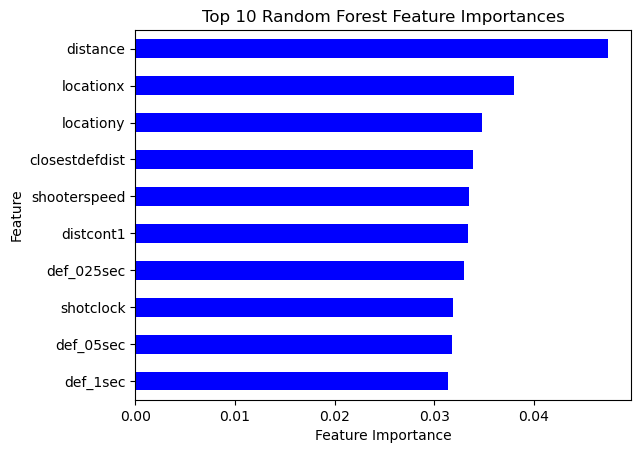

In [62]:
# Visualizing what the model considers important features
importance = pd.Series(
    clf.feature_importances_,
    index = X_train.columns
).sort_values(ascending = False)

importance.head(10).sort_values().plot(kind = 'barh', color = 'blue')

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 10 Random Forest Feature Importances')
plt.show()

### Cleaning testing.csv

In [ ]:
# Turning closestdefapproach into a column for each 0.25 second again

test_df[['def_1sec', 'def_075sec', 'def_05sec', 'def_025sec']] = (
    test_df['closestdefapproach']
    .str.strip('{}')
    .str.split(',', expand = True)
    .astype(float)
)

In [ ]:
# Turning the letter codes of teams, shooters defenders, month, gamestate, and shottype into columns of 0s and 1s
# so they become usable for the math formulas in the models

encoded = encoder.transform(
    test_df[['shooter_id', 
              'off_team_id', 
              'def_team_id',
              'closestdef_id', 
              'contester1_id', 
              'contester2_id', 
              'contester3_id', 
              'contester4_id', 
              'month',
             'gamestate', 
              'shottype']]
)

encoded_df = pd.DataFrame.sparse.from_spmatrix(
    encoded,
    columns = encoder.get_feature_names_out(['shooter_id', 
              'off_team_id', 
              'def_team_id',
              'closestdef_id', 
              'contester1_id', 
              'contester2_id', 
              'contester3_id', 
              'contester4_id', 
              'month',
             'gamestate', 
              'shottype']),
    index = test_df.index
)

test_df = pd.concat(
    [test_df.drop(columns = ['shooter_id', 
              'off_team_id', 
              'def_team_id',
              'closestdef_id', 
              'contester1_id', 
              'contester2_id', 
              'contester3_id', 
              'contester4_id', 
              'month',
             'gamestate', 
              'shottype']), encoded_df],
    axis = 1
)

In [22]:
# Dropping shot_id, season_id, closestdefapproach since they now have columns for each entry
test_df = test_df.drop(columns = ['shot_id', 'season_id', 'closestdefapproach'])

In [24]:
# Calculating final probabilities for make_prob
y_pred_final = clf.predict_proba(test_df)[:, 1]

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\utils\validation.py:877: UserWarning: pandas.DataFrame with sparse columns found.It will be converted to a dense numpy array.
  warnings.warn(


## RandomForestClassifier Results

In [27]:
pd.Series(y_pred_final).describe()

count    213977.000000
mean          0.444697
std           0.183522
min           0.000000
25%           0.320000
50%           0.400000
75%           0.520000
max           1.000000
dtype: float64

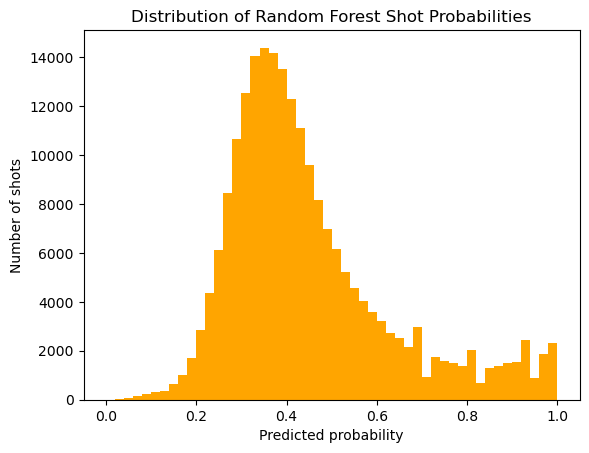

In [64]:
plt.hist(y_pred_final, bins = 50, color = 'orange')
plt.xlabel('Predicted probability')
plt.ylabel('Number of shots')
plt.title('Distribution of Random Forest Shot Probabilities')
plt.show()

### Saving RandomForestClassifier Results

In [ ]:
np.savetxt('shotmake_probs.csv', y_pred_final, delimiter=',')

# Logistic Regression

In [164]:
from sklearn.linear_model import LogisticRegression
log_clf = LogisticRegression(random_state = 13, solver = 'saga', max_iter = 1000)

In [166]:
# Copying data since I need to make changes.
X_train_logreg = X_train.copy()
X_test_logreg = X_test.copy()
y_train_logreg = y_train.copy()
y_test_logreg = y_test.copy()

### Data Cleaning

In [168]:
# Converting NaN's to zeros, since log regression can't handle NaN's
for col in ['distcont1', 'distcont2', 'distcont3', 'distcont4']:
    X_train_logreg[col] = X_train_logreg[col].fillna(0)
    X_test_logreg[col] = X_test_logreg[col].fillna(0)

In [170]:
from sklearn.preprocessing import StandardScaler

# Converting columns to a similar scale to make the model run faster
numeric_cols = [
    'distance',
    'locationx',
    'locationy',
    'shotclock',
    'distcont1',
    'distcont2',
    'distcont3',
    'distcont4',
    'closestdefdist',
    'dribblesbefore'
]

scaler = StandardScaler()

X_train_logreg[numeric_cols] = scaler.fit_transform(
    X_train_logreg[numeric_cols]
)

X_test_logreg[numeric_cols] = scaler.transform(
    X_test_logreg[numeric_cols]
)

In [172]:
# Converting to a sparse matrix, where it won't have to store all of my one-hot encoded zeros from their columns.
# This will also help the model run faster.

from scipy.sparse import csr_matrix

X_train_logreg_sparse = csr_matrix(
    X_train_logreg.astype(pd.SparseDtype("float64", 0))
)

X_test_logreg_sparse = csr_matrix(
    X_test_logreg.astype(pd.SparseDtype("float64", 0))
)

In [176]:
# Unraveling y from the form of (340575, 1) to (340575,)
# Helping model run faster as well.

y_train_logreg = y_train_logreg.values.ravel()
y_test_logreg = y_test_logreg.values.ravel()

# Logistic Regression Model Training

In [178]:
log_y_pred = log_clf.fit(X_train_logreg_sparse, y_train_logreg)

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [180]:
log_y_pred = log_clf.predict_proba(X_test_logreg_sparse)[:, 1]

In [184]:
# logloss result from Logistic Regression training
print(log_loss(y_test_logreg, log_y_pred))

0.6333995518511182


# Logistic Regression Model Prediction

In [132]:
X_logreg = X.copy()
test_df_logreg = test_df.copy()

### Cleaning testing.csv for Logistic Regression

In [134]:
# Converting NaN's to zeros, since log regression can't handle NaN's
for col in ['distcont1', 'distcont2', 'distcont3', 'distcont4']:
    X_logreg[col] = X_logreg[col].fillna(0)
    test_df_logreg[col] = test_df_logreg[col].fillna(0)

In [136]:
# Converting columns to a similar scale to make the model run faster
numeric_cols = [
    'distance',
    'locationx',
    'locationy',
    'shotclock',
    'distcont1',
    'distcont2',
    'distcont3',
    'distcont4',
    'closestdefdist',
    'dribblesbefore'
]

scaler = StandardScaler()

X_logreg[numeric_cols] = scaler.fit_transform(
    X_logreg[numeric_cols]
)

test_df_logreg[numeric_cols] = scaler.transform(
    test_df_logreg[numeric_cols]
)

In [138]:
# Converting to a sparse matrix, where it won't have to store all of my one-hot encoded zeros from their columns.
# This will also help the model run faster.

X_logreg_sparse = csr_matrix(
    X_logreg.astype(pd.SparseDtype("float64", 0))
)

test_df_logreg_sparse = csr_matrix(
    test_df_logreg.astype(pd.SparseDtype("float64", 0))
)

In [142]:
y_logreg = y.values.ravel()

# Logistic Regression Model Prediction

In [144]:
log_clf.fit(X_logreg_sparse, y_logreg)

C:\Users\pgleh\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(max_iter=1000, random_state=13, solver='saga')

In [146]:
# Calculating final probabilities for submission
y_pred_final_logreg = log_clf.predict_proba(test_df_logreg_sparse)[:, 1]

## Logistic Regression Results

In [219]:
pd.Series(y_pred_final_logreg).describe()

count    213977.000000
mean          0.456628
std           0.166643
min           0.000715
25%           0.342166
50%           0.425350
75%           0.531325
max           0.999962
dtype: float64

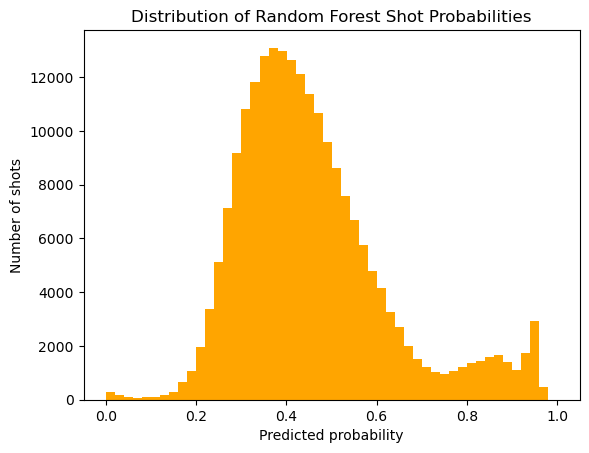

In [160]:
plt.hist(y_pred_final_logreg, bins = 50, color = 'orange')
plt.xlabel('Predicted probability')
plt.ylabel('Number of shots')
plt.title('Distribution of Random Forest Shot Probabilities')
plt.show()

### Saving Results

In [ ]:
np.savetxt('shotmake_probs_logreg.csv', y_pred_final_logreg, delimiter=',') 